In [4]:
!pip install gensim
from gensim.models import Word2Vec
# Sample document corpus
corpus = [
 ["machine", "learning", "is", "fun"],
 ["deep", "learning", "uses", "neural", "networks"],
 ["deep", "learning"]
]
# Train the Word2Vec model
model = Word2Vec(
 sentences=corpus,
 vector_size=50, # Size of word embeddings
 window=2, # Context window size
 min_count=1, # Include all words
 workers=1
)
# Print the embedding vector for a word
print("Embedding for 'learning':")
print(model.wv["learning"])
# Find similar words
print("\nWords similar to 'learning':")
print(model.wv.most_similar("learning"))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 9.2 MB/s  0:00:03
Embedding for 'learning':
[-1.0724545e-03  4.7286271e-04  1.0206699e-02  1.8018546e-02
 -1.8605899e-02 -1.4233618e-02  1.2917745e-02  1.7945977e-02
 -1.0030856e-02 -7.5267432e-03  1.4761009e-02 -3.0669428e-03
 -9.0732267e-03  1.3108104e-02 -9.7203208e-03 -3.6320353e-03
  5.7531595e-03  1.9837476e-03 -1.6570430e-02 -1.8897636e-02
  1.4623532e-02  1.0140524e-02  1.3515387e-02  1.5257311e-03
  1.2701781e-02 -6.8107317e-03 -1.8928028e-03  1.1537147e-02
 -1.5043275e-02 -7.8722071e-03 -1.5023164e-02 -1.8600845e-03
  1.9076237e-02 -1.4638334e-02 -4.6675373e-03 -3.8754821e-03
  1.6154874e-02 -1.1861792e-02  9.0324880e-05 -9.5074680e-03
 -1.9207101e-02  1.0014586e-02 -1.7519170e-02 -8.7836506e-03
 -7.0199967e-05 -5.9236289e-04 -1.5322480e-02  1.9229487e-02
  9.9641159e-03  1.8466286e-02]

Words similar to 'learning':
[('machine', 0.13204392790794373), ('networks', 0.1267007291316986), ('deep', 0.042373016476631165), ('fu

In [5]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
# Load Iris dataset
iris = load_iris()
X = iris.data
y = iris.target
# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.2, random_state=42
)
# Standardize the features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
# Build the Deep Neural Network
model = Sequential([
 Dense(16, activation='relu', input_shape=(4,)),
 Dense(12, activation='relu'),
 Dense(8, activation='relu'),
 Dense(3, activation='softmax') # 3 output classes
])
# Compile the model
model.compile(
 optimizer='adam',
 loss='sparse_categorical_crossentropy',
 metrics=['accuracy']
)
# Display model summary
model.summary()
# Train the model
model.fit(X_train, y_train, epochs=50, batch_size=8, verbose=1)
# Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
#print("\nTest Accuracy:", accuracy)
print(f"\nTest Accuracy: {accuracy * 100:.2f}%") # Predict on test data
predictions = model.predict(X_test)
predicted_classes = np.argmax(predictions, axis=1)
print("\nPredicted Classes:", predicted_classes)
print("Actual Classes :", y_test)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │           204 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 415 (1.62 KB)

 Trainable params: 415 (1.62 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3333 - loss: 1.1465
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3417 - loss: 1.0394  
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4083 - loss: 0.9578 
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5333 - loss: 0.8827 
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6167 - loss: 0.8129 
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6583 - loss: 0.7516 
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6750 - loss: 0.7046 
Epoch 8/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6917 - loss: 0.6659 
Epoch 9/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7083 - loss: 0.6338 
Epoch 10/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7167 - loss: 0.6038 
Epoch 11/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7500 - loss: 0.5772 
Epoch 12/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 

In [6]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
# Load Iris dataset
iris = load_iris()
X = iris.data
y = iris.target
# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.2, random_state=42
)
# Standardize the features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
# Build the Deep Neural Network
model = Sequential([
 Dense(16, activation='relu', input_shape=(4,)),
 Dense(12, activation='relu'),
 Dense(8, activation='relu'),
 Dense(3, activation='softmax') # 3 output classes
])
# Compile the model
model.compile(
 optimizer='adam',
 loss='sparse_categorical_crossentropy',
 metrics=['accuracy']
)
# Display model summary
model.summary()
# Train the model
model.fit(X_train, y_train, epochs=50, batch_size=8, verbose=1)
# Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
#print("\nTest Accuracy:", accuracy)
print(f"\nTest Accuracy: {accuracy * 100:.2f}%") # Predict on test data
predictions = model.predict(X_test)
predicted_classes = np.argmax(predictions, axis=1)
print("\nPredicted Classes:", predicted_classes)
print("Actual Classes :", y_test)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 12)             │           204 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 415 (1.62 KB)

 Trainable params: 415 (1.62 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.3417 - loss: 1.1965
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.3583 - loss: 1.0906
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4500 - loss: 1.0050
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6417 - loss: 0.9196 
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7667 - loss: 0.8325 
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7583 - loss: 0.7567
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7500 - loss: 0.6810 
Epoch 8/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7583 - loss: 0.6161 
Epoch 9/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7750 - loss: 0.5596  
Epoch 10/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8000 - loss: 0.5176 
Epoch 11/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8083 - loss: 0.4800
Epoch 12/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - loss: 0.2748
Epoch 2/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.1719
Epoch 3/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.1460
Epoch 4/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.1301
Epoch 5/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.1195
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


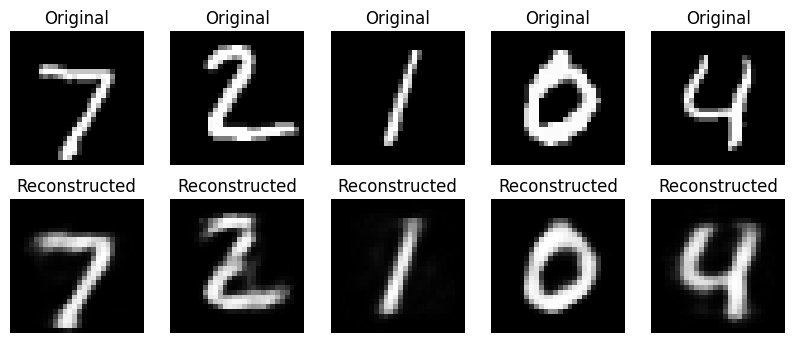

Original size: (10000, 784)
Compressed size: (10000, 32)


In [7]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, Model
# Load dataset
(x_train, _), (x_test, _) = tf.keras.datasets.mnist.load_data()
# Normalize and flatten
x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)
# Input
input_img = layers.Input(shape=(784,))
# Encoder - compression
encoded = layers.Dense(32, activation="relu")(input_img)
# Decoder - reconstruction
decoded = layers.Dense(784, activation="sigmoid")(encoded)
# Autoencoder
model = Model(input_img, decoded)
# Compile
model.compile(optimizer="adam", loss="binary_crossentropy")
# Train
model.fit(x_train, x_train, epochs=5, batch_size=256)
# Encoder model
encoder = Model(input_img, encoded)
# Compressed images
encoded_imgs = encoder.predict(x_test)
# Reconstructed images
decoded_imgs = model.predict(x_test)
# Display original and reconstructed images
n = 5
plt.figure(figsize=(10, 4))
for i in range(n): # Original
 ax = plt.subplot(2, n, i + 1)
 plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
 plt.title("Original")
 plt.axis('off')
 # Reconstructed
 ax = plt.subplot(2, n, i + 1 + n)
 plt.imshow(decoded_imgs[i].reshape(28, 28), cmap='gray')
 plt.title("Reconstructed")
 plt.axis('off')
plt.show()
# Display sizes
print("Original size:", x_test.shape)
print("Compressed size:", encoded_imgs.shape)

In [10]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Embedding, GlobalAveragePooling1D, Dense
# 1. Load IMDB dataset (Movie Reviews)
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.imdb.load_data(
 num_words=10000
)
# 2. Make all reviews the same length
x_train = tf.keras.preprocessing.sequence.pad_sequences(
 x_train, maxlen=200
)
x_test = tf.keras.preprocessing.sequence.pad_sequences(
 x_test, maxlen=200
)
# 3. Create deep learning model
model = Sequential([
 Embedding(10000, 32),
 GlobalAveragePooling1D(),
 Dense(64, activation='relu'),
 Dense(1, activation='sigmoid')
])
# 4. Compile model
model.compile(
 optimizer='adam',
 loss='binary_crossentropy',
 metrics=['accuracy']
)
# 5. Train model
model.fit(
 x_train,
 y_train,
 epochs=5,
 batch_size=32,
 validation_split=0.2
)
# 6. Test model
loss, accuracy = model.evaluate(x_test, y_test)
print("Test Accuracy:", accuracy)
# 7. Predict first 5 reviews
predictions = model.predict(x_test[:5])
print("\nReview Classification:")
for i in range(5):
 if predictions[i][0] >= 0.5:
  result = "Positive"
 else:
  result = "Negative"
 print("Review", i + 1, ":", result)
 print("Probability:", predictions[i][0])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.7744 - loss: 0.4745 - val_accuracy: 0.8676 - val_loss: 0.3198
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.8885 - loss: 0.2693 - val_accuracy: 0.8574 - val_loss: 0.3224
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9192 - loss: 0.2047 - val_accuracy: 0.8752 - val_loss: 0.2975
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9355 - loss: 0.1717 - val_accuracy: 0.8820 - val_loss: 0.3032
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.9456 - loss: 0.1473 - val_accuracy: 0.8790 - val_loss: 0.3318
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8606 - loss: 0.3629
Test Accuracy: 0.8605599999427795
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step

Review Classification:
Review 1 : Negative
Probability: 0.03241968
Review 2 : Positive
Probability: 0.9998706
Review 3 : Positive
Probability: 0.6816523
Review 4 : N

In [14]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
# 1. Load CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()
# Convert labels to 1D
y_train = y_train.flatten()
y_test = y_test.flatten()
# 2. Resize images
x_train = tf.image.resize(x_train, (96, 96))
x_test = tf.image.resize(x_test, (96, 96))
# 3. Load pre-trained MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
 input_shape=(96, 96, 3),
 include_top=False,
 weights="imagenet"
)
# Freeze pre-trained layers
base_model.trainable = False
# 4. Create model
model = tf.keras.Sequential([
 base_model,
 tf.keras.layers.GlobalAveragePooling2D(),
 tf.keras.layers.Dense(64, activation="relu"),
 tf.keras.layers.Dense(10, activation="softmax")
])
# 5. Compile
model.compile(
 optimizer="adam",
 loss="sparse_categorical_crossentropy",
 metrics=["accuracy"]
)
# 6. Train
history = model.fit(
 x_train,
 y_train,
 epochs=5,
 batch_size=32,
 validation_split=0.2
)
# 7. Test model
loss, accuracy = model.evaluate(x_test, y_test)
print("Test Accuracy:", accuracy * 100, "%")
# 8. Predict one image
prediction = model.predict(x_test[:1])
classes = [
 "airplane", "automobile", "bird", "cat", "deer",
 "dog", "frog", "horse", "ship", "truck"
]
predicted_class = np.argmax(prediction)
print("Actual:", classes[y_test[0]])
print("Predicted:", classes[predicted_class])
# Print final training and validation accuracy
train_accuracy = history.history["accuracy"][-1]
val_accuracy = history.history["val_accuracy"][-1]
print("Training Accuracy:", train_accuracy * 100, "%")
print("Validation Accuracy:", val_accuracy * 100, "%")
# Test accuracy
loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print("Test Accuracy:", test_accuracy * 100, "%")
# Accuracy graph
plt.figure(figsize=(8, 5))
plt.plot(
 history.history["accuracy"],
 label="Training Accuracy"
)
plt.plot(
 history.history["val_accuracy"],
 label="Validation Accuracy"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

    40960/170498071 ━━━━━━━━━━━━━━━━━━━━ 41:01 14us/step

KeyboardInterrupt: 

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
# Dataset
reviews = [
 "I loved this movie, it was fantastic",
 "The product is excellent and very useful",
 "Amazing experience, I really enjoyed it",
 "The service was wonderful",
 "Very happy with my purchase",
 "This product is terrible",
 "I hated this movie",
 "Very disappointing experience",
 "The product broke after one day",
 "Poor quality and bad service"
]
# Labels: 1 = Positive, 0 = Negative
labels = [
 1, 1, 1, 1, 1,
 0, 0, 0, 0, 0
]
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
 reviews,
 labels,
 test_size=0.2,
 random_state=42,
 stratify=labels
)
# Convert text into TF-IDF features
vectorizer = TfidfVectorizer()
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)
# Train the model
model = LogisticRegression()
model.fit(X_train_tfidf, y_train)
# Predict test data
y_pred = model.predict(X_test_tfidf) # Test new reviews
new_reviews = [
 "The movie was amazing and I loved it",
 "The product was awful and disappointing",
 "I am very happy with this purchase"
]
new_reviews_tfidf = vectorizer.transform(new_reviews)
predictions = model.predict(new_reviews_tfidf)
# Display results
for review, prediction in zip(new_reviews, predictions):
 sentiment = "Positive" if prediction == 1 else "Negative"
 print("\nReview:", review)
 print("Sentiment:", sentiment)


Review: The movie was amazing and I loved it
Sentiment: Positive

Review: The product was awful and disappointing
Sentiment: Positive

Review: I am very happy with this purchase
Sentiment: Negative
